# Proyek Analisis Data: Bike Sharing Dataset
- **Nama: Muhammad Fawwaz Zildan**
- **Email: ds296b6y1159@student.devacademy.id**
- **ID Dicoding: ds296b6y1159**

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa rata-rata jumlah penyewaan sepeda mencapai puncaknya selama periode Januari 2011 hingga Desember 2012?

- **Pertanyaan 2:** Berapa perbedaan rata-rata jumlah penyewaan sepeda antara hari kerja (*working day*) dan hari nonkerja (*non-working day*) selama periode Januari 2011 hingga Desember 2012?

- **Pertanyaan 3:** Pada bulan apa total penyewaan sepeda mencapai jumlah tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?

- **Pertanyaan 4:** Kondisi cuaca apa yang memiliki rata-rata jumlah penyewaan sepeda tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?

## Import Semua Packages/Library yang Digunakan

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

## Data Wrangling

### Gathering Data

### Memuat Dataset Bike Sharing

Dataset yang digunakan adalah Bike Sharing. Dataset terdiri dari dua file utama, yaitu:

- day.csv: Berisi data penyewaan sepeda berdasarkan tanggal atau harian.
- hour.csv: Berisi data penyewaan sepeda berdasarkan jam.

In [74]:
zip_path = "/content/Bike-sharing-dataset.zip"
extract_path = "/content/bike_sharing_data"

def cari_csv(folder):
    day_path = None
    hour_path = None

    if os.path.isdir(folder):
        for root, dirs, files in os.walk(folder):
            if "day.csv" in files:
                day_path = os.path.join(root, "day.csv")
            if "hour.csv" in files:
                hour_path = os.path.join(root, "hour.csv")

    return day_path, hour_path

day_path, hour_path = cari_csv(extract_path)

if day_path is not None and hour_path is not None:
    print("Dataset sudah diekstrak. Langsung membaca CSV.")

else:
    if os.path.isfile(zip_path):
        print("Mengekstrak dataset ZIP...")

        os.makedirs(extract_path, exist_ok=True)

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(extract_path)

        day_path, hour_path = cari_csv(extract_path)

    else:
        raise FileNotFoundError(
            "Dataset tidak ditemukan."
        )

if day_path is None or hour_path is None:
    raise FileNotFoundError(
        "File day.csv atau hour.csv tidak ditemukan."
    )

df_day = pd.read_csv(day_path)
df_hour = pd.read_csv(hour_path)

print("Dataset berhasil dimuat!")
print("Data harian:", df_day.shape)
print("Data per jam:", df_hour.shape)

display(df_day.head())
display(df_hour.head())

Dataset sudah diekstrak. Langsung membaca CSV.
Dataset berhasil dimuat!
Data harian: (731, 16)
Data per jam: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset day.csv digunakan untuk menganalisis pola penyewaan sepeda berdasarkan tanggal, bulan, hari kerja, dan kondisi cuaca.
- Dataset hour.csv digunakan untuk menganalisis pola penyewaan sepeda berdasarkan jam.
- Kedua dataset memiliki tingkat detail waktu yang berbeda sehingga akan dianalisis secara terpisah.

### Assessing Data

#### Memeriksa kualitas data
pemeriksaan terhadap kedua dataset untuk mengetahui apakah terdapat permasalahan kualitas data. Pemeriksaan meliputi tipe data, nilai kosong, data duplikat, serta informasi statistik dari setiap kolom.

In [75]:
print("Informasi Dataset Harian:")
df_day.info()

print("\nJumlah Missing Values Dataset Harian:")
print(df_day.isnull().sum())

print("\nJumlah Data Duplikat Dataset Harian:")
print(df_day.duplicated().sum())

print("\nStatistik Deskriptif Dataset Harian:")
display(df_day.describe())

print("\nInformasi Dataset Per Jam:")
df_hour.info()

print("\nJumlah Missing Values Dataset Per Jam:")
print(df_hour.isnull().sum())

print("\nJumlah Data Duplikat Dataset Per Jam:")
print(df_hour.duplicated().sum())

print("\nStatistik Deskriptif Dataset Per Jam:")
display(df_hour.describe())

Informasi Dataset Harian:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Jumlah Missing Values Dataset Harian:
instant       0
dteday      

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



Informasi Dataset Per Jam:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Jumlah Missing Value

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Pemeriksaan nilai tidak valid, konsistensi, dan outlier


=== Dataset Harian ===
Jumlah penyewaan negatif: 0
Jumlah penyewaan tidak konsisten: 0
Kategori hari kerja tidak valid: 0
Kategori cuaca tidak valid: 0
Kategori bulan tidak valid: 0
Batas bawah/atas IQR: -1054.00 / 10162.00
Jumlah outlier penyewaan (IQR): 0

=== Dataset Per Jam ===
Jumlah penyewaan negatif: 0
Jumlah penyewaan tidak konsisten: 0
Kategori hari kerja tidak valid: 0
Kategori cuaca tidak valid: 0
Kategori bulan tidak valid: 0
Jam tidak valid: 0
Batas bawah/atas IQR: -321.50 / 642.50
Jumlah outlier penyewaan (IQR): 505


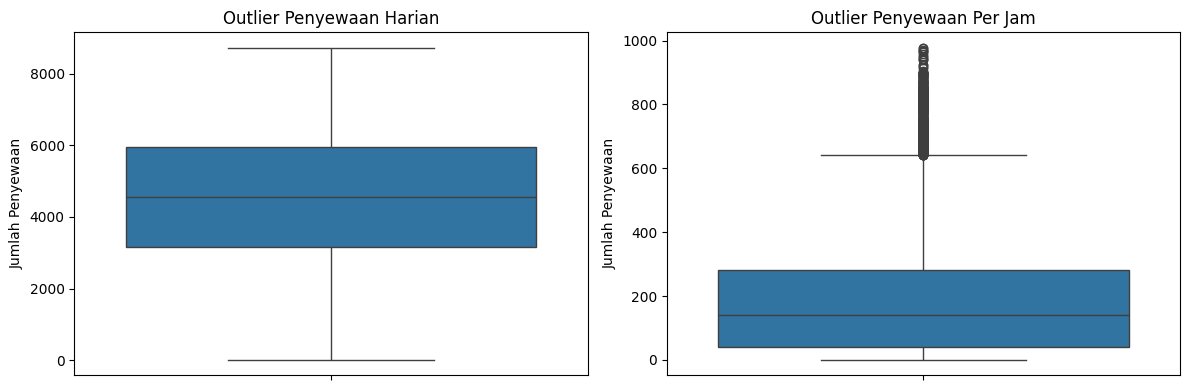

In [76]:
for nama_dataset, data in [("Harian", df_day), ("Per Jam", df_hour)]:
    print(f"\n=== Dataset {nama_dataset} ===")
    print("Jumlah penyewaan negatif:", (data["cnt"] < 0).sum())
    print("Jumlah penyewaan tidak konsisten:",
          (data["casual"] + data["registered"] != data["cnt"]).sum())
    print("Kategori hari kerja tidak valid:",
          (~data["workingday"].isin([0, 1])).sum())
    print("Kategori cuaca tidak valid:",
          (~data["weathersit"].isin([1, 2, 3, 4])).sum())
    print("Kategori bulan tidak valid:",
          (~data["mnth"].between(1, 12)).sum())
    if "hr" in data.columns:
        print("Jam tidak valid:", (~data["hr"].between(0, 23)).sum())

    q1 = data["cnt"].quantile(0.25)
    q3 = data["cnt"].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah_outlier = ((data["cnt"] < batas_bawah) |
                      (data["cnt"] > batas_atas)).sum()
    print(f"Batas bawah/atas IQR: {batas_bawah:.2f} / {batas_atas:.2f}")
    print("Jumlah outlier penyewaan (IQR):", jumlah_outlier)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df_day["cnt"], ax=axes[0])
axes[0].set_title("Outlier Penyewaan Harian")
axes[0].set_ylabel("Jumlah Penyewaan")
sns.boxplot(y=df_hour["cnt"], ax=axes[1])
axes[1].set_title("Outlier Penyewaan Per Jam")
axes[1].set_ylabel("Jumlah Penyewaan")
plt.tight_layout()
plt.show()

**Steps to Take:**

- Memeriksa tipe data pada setiap kolom untuk memastikan kesesuaiannya.
- Mengidentifikasi jumlah nilai kosong pada setiap kolom.
- Memeriksa keberadaan data duplikat.
- Mengamati statistik deskriptif untuk mengetahui gambaran umum distribusi data.
- Mengubah tipe data kolom dteday menjadi datetime agar dapat digunakan dalam analisis berdasarkan waktu.
- Memeriksa nilai tidak valid, konsistensi total penyewaan, dan outlier IQR pada jumlah penyewaan.
- Menentukan tindakan cleaning berdasarkan hasil pemeriksaan, bukan menghapus data tanpa alasan.

**Insight:** (Opsional)
- Kedua dataset tidak memiliki nilai kosong.
- Tidak ditemukan data duplikat pada dataset harian maupun dataset per jam.
- Kolom dteday pada kedua dataset masih memiliki tipe data object, sehingga perlu dikonversi menjadi datetime.
- Secara umum, struktur kedua dataset sudah cukup baik dan dapat digunakan untuk analisis setelah dilakukan penyesuaian tipe data tanggal.
- Pemeriksaan IQR menemukan outlier pada data per jam. Outlier tidak otomatis merupakan kesalahan pencatatan, sehingga diperiksa dan dipertahankan untuk analisis.

### Cleaning Data

#### Memperbaiki Tipe Data Tanggal

In [77]:
df_day["dteday"] = pd.to_datetime(df_day["dteday"])
df_hour["dteday"] = pd.to_datetime(df_hour["dteday"])

nama_kolom_indonesia = {
    "instant": "id_data",
    "dteday": "tanggal",
    "season": "musim",
    "yr": "tahun",
    "mnth": "bulan",
    "hr": "jam",
    "holiday": "hari_libur",
    "weekday": "hari_dalam_pekan",
    "workingday": "hari_kerja",
    "weathersit": "kondisi_cuaca",
    "temp": "suhu_normalisasi",
    "atemp": "suhu_terasa_normalisasi",
    "hum": "kelembapan_normalisasi",
    "windspeed": "kecepatan_angin_normalisasi",
    "casual": "pengguna_kasual",
    "registered": "pengguna_terdaftar",
    "cnt": "jumlah_penyewaan"
}

df_day = df_day.rename(columns=nama_kolom_indonesia)
df_hour = df_hour.rename(columns=nama_kolom_indonesia)

print("Kolom dataset harian:", list(df_day.columns))
print("Kolom dataset per jam:", list(df_hour.columns))
print("Tipe tanggal harian:", df_day["tanggal"].dtype)
print("Tipe tanggal per jam:", df_hour["tanggal"].dtype)

Kolom dataset harian: ['id_data', 'tanggal', 'musim', 'tahun', 'bulan', 'hari_libur', 'hari_dalam_pekan', 'hari_kerja', 'kondisi_cuaca', 'suhu_normalisasi', 'suhu_terasa_normalisasi', 'kelembapan_normalisasi', 'kecepatan_angin_normalisasi', 'pengguna_kasual', 'pengguna_terdaftar', 'jumlah_penyewaan']
Kolom dataset per jam: ['id_data', 'tanggal', 'musim', 'tahun', 'bulan', 'jam', 'hari_libur', 'hari_dalam_pekan', 'hari_kerja', 'kondisi_cuaca', 'suhu_normalisasi', 'suhu_terasa_normalisasi', 'kelembapan_normalisasi', 'kecepatan_angin_normalisasi', 'pengguna_kasual', 'pengguna_terdaftar', 'jumlah_penyewaan']
Tipe tanggal harian: datetime64[ns]
Tipe tanggal per jam: datetime64[ns]


### Validasi Hasil Cleaning

In [78]:
for nama_dataset, data in [("Harian", df_day), ("Per Jam", df_hour)]:
    print(f"\n=== Validasi Dataset {nama_dataset} ===")
    print("Nilai kosong:", data.isna().sum().sum())
    print("Baris duplikat:", data.duplicated().sum())
    print("Tanggal bertipe datetime:", pd.api.types.is_datetime64_any_dtype(data["tanggal"]))
    print("Jumlah penyewaan negatif:", (data["jumlah_penyewaan"] < 0).sum())
    print("Jumlah tidak konsisten:", (data["pengguna_kasual"] + data["pengguna_terdaftar"] != data["jumlah_penyewaan"]).sum())


=== Validasi Dataset Harian ===
Nilai kosong: 0
Baris duplikat: 0
Tanggal bertipe datetime: True
Jumlah penyewaan negatif: 0
Jumlah tidak konsisten: 0

=== Validasi Dataset Per Jam ===
Nilai kosong: 0
Baris duplikat: 0
Tanggal bertipe datetime: True
Jumlah penyewaan negatif: 0
Jumlah tidak konsisten: 0


**Insight:** (Opsional)
- Kolom dteday pada dataset harian dan per jam berhasil dikonversi menjadi tipe data datetime.
- Konversi ini memungkinkan data tanggal digunakan untuk analisis berdasarkan waktu, seperti pengelompokan berdasarkan bulan dan tahun.
- Tidak diperlukan penanganan missing values maupun data duplikat karena kedua permasalahan tersebut tidak ditemukan pada tahap Accessing Data.
- Seluruh nama kolom diubah ke Bahasa Indonesia
- Outlier pada penyewaan per jam dipertahankan karena dapat merupakan permintaan nyata.

### Menyimpan data yang sudah dibersihkan

In [79]:
df_day.to_csv('main_data.csv', index=False)
df_hour.to_csv('hour_data.csv', index=False)

print("Dataset hasil cleaning berhasil disimpan!")

Dataset hasil cleaning berhasil disimpan!


## Exploratory Data Analysis (EDA)

### Eksplorasi Pola Penyewaan Sepeda

In [80]:
print("Rentang Tanggal Dataset Harian:")
print(df_day['tanggal'].min(), "hingga", df_day['tanggal'].max())

print("\nRentang Tanggal Dataset Per Jam:")
print(df_hour['tanggal'].min(), "hingga", df_hour['tanggal'].max())

print("\nJumlah Penyewaan Berdasarkan Tahun:")
display(df_day.groupby('tahun')['jumlah_penyewaan'].sum())

print("\nRata-rata Penyewaan Berdasarkan Jam:")
display(
    df_hour.groupby('jam')['jumlah_penyewaan']
    .mean()
    .sort_values(ascending=False)
)

print("\nRata-rata Penyewaan Berdasarkan Hari Kerja:")
display(df_day.groupby('hari_kerja')['jumlah_penyewaan'].mean())

print("\nTotal Penyewaan Berdasarkan Tahun dan Bulan:")
display(
    df_day.groupby(['tahun', 'bulan'])['jumlah_penyewaan']
    .sum()
    .reset_index()
)

print("\nRata-rata Penyewaan Berdasarkan Kondisi Cuaca:")
display(df_day.groupby('kondisi_cuaca')['jumlah_penyewaan'].mean())

Rentang Tanggal Dataset Harian:
2011-01-01 00:00:00 hingga 2012-12-31 00:00:00

Rentang Tanggal Dataset Per Jam:
2011-01-01 00:00:00 hingga 2012-12-31 00:00:00

Jumlah Penyewaan Berdasarkan Tahun:


,jumlah_penyewaan
tahun,
0,1243103
1,2049576



Rata-rata Penyewaan Berdasarkan Jam:


,jumlah_penyewaan
jam,
17,461.452055
18,425.510989
8,359.011004
16,311.983562
19,311.523352
13,253.661180
12,253.315934
15,251.233196
14,240.949246



Rata-rata Penyewaan Berdasarkan Hari Kerja:


,jumlah_penyewaan
hari_kerja,
0,4330.168831
1,4584.820000



Total Penyewaan Berdasarkan Tahun dan Bulan:


,tahun,bulan,jumlah_penyewaan
0,0,1,38189
1,0,2,48215
2,0,3,64045
3,0,4,94870
4,0,5,135821
5,0,6,143512
6,0,7,141341
7,0,8,136691
8,0,9,127418
9,0,10,123511



Rata-rata Penyewaan Berdasarkan Kondisi Cuaca:


,jumlah_penyewaan
kondisi_cuaca,
1,4876.786177
2,4035.862348
3,1803.285714


**Insight:** (Opsional)
- Rentang data pada kedua dataset mencakup periode 1 Januari 2011 hingga 31 Desember 2012.
- Total penyewaan sepeda mengalami peningkatan dari 1.243.103 pada tahun 2011 menjadi 2.049.576 pada tahun 2012.
- Rata-rata penyewaan sepeda tertinggi berdasarkan jam terjadi pada pukul 17.00, sedangkan rata-rata terendah terjadi pada pukul 04.00.
- Rata-rata penyewaan pada hari kerja sebesar 4.584,82, lebih tinggi dibandingkan hari nonkerja sebesar 4.330,17.
- Total penyewaan bulanan tertinggi terjadi pada September 2012 dengan 218.573 penyewaan, sedangkan terendah terjadi pada Januari 2011 dengan 38.189 penyewaan.
- Berdasarkan kondisi cuaca, kategori 1 memiliki rata-rata penyewaan tertinggi sebesar 4.876,79, sedangkan kategori 3 memiliki rata-rata terendah sebesar 1.803,29.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Pada jam berapa rata-rata jumlah penyewaan sepeda mencapai puncaknya selama periode Januari 2011 hingga Desember 2012?

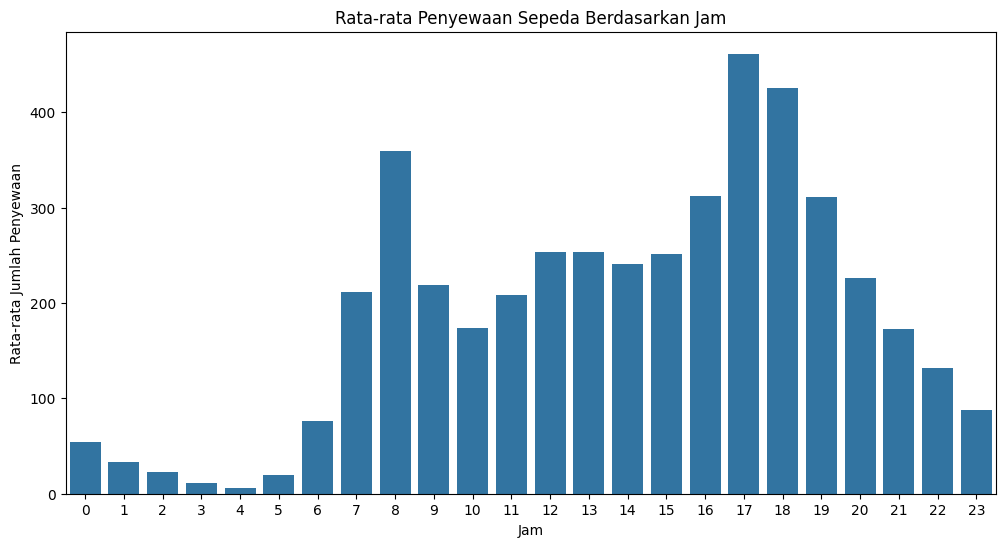

In [81]:
rata_per_jam = df_hour.groupby('jam')['jumlah_penyewaan'].mean().reset_index()


plt.figure(figsize=(12, 6))
sns.barplot(data=rata_per_jam, x='jam', y='jumlah_penyewaan')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Jam')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.show()

### Pertanyaan 2:
Berapa perbedaan rata-rata jumlah penyewaan sepeda antara hari kerja (working day) dan hari nonkerja (non-working day) selama periode Januari 2011 hingga Desember 2012?

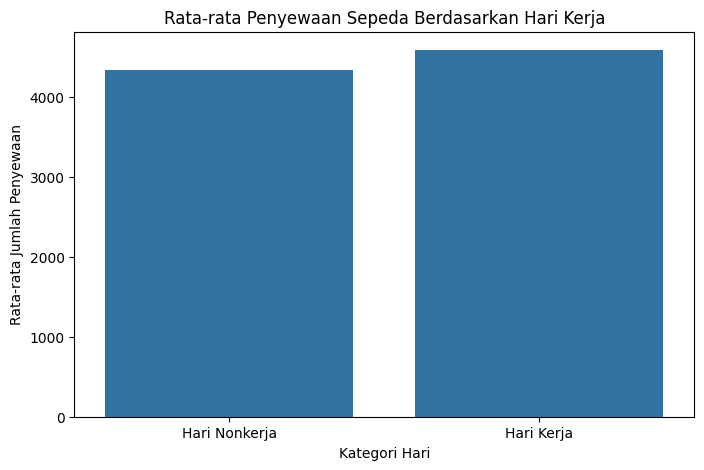

In [82]:
rata_hari_kerja = df_day.groupby('hari_kerja')['jumlah_penyewaan'].mean().reset_index()

rata_hari_kerja['hari_kerja'] = rata_hari_kerja['hari_kerja'].map({
    0: 'Hari Nonkerja',
    1: 'Hari Kerja'
})

plt.figure(figsize=(8, 5))
sns.barplot(data=rata_hari_kerja, x='hari_kerja', y='jumlah_penyewaan')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Hari Kerja')
plt.xlabel('Kategori Hari')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.show()

### Pertanyaan 3:
Pada bulan apa total penyewaan sepeda mencapai jumlah tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?

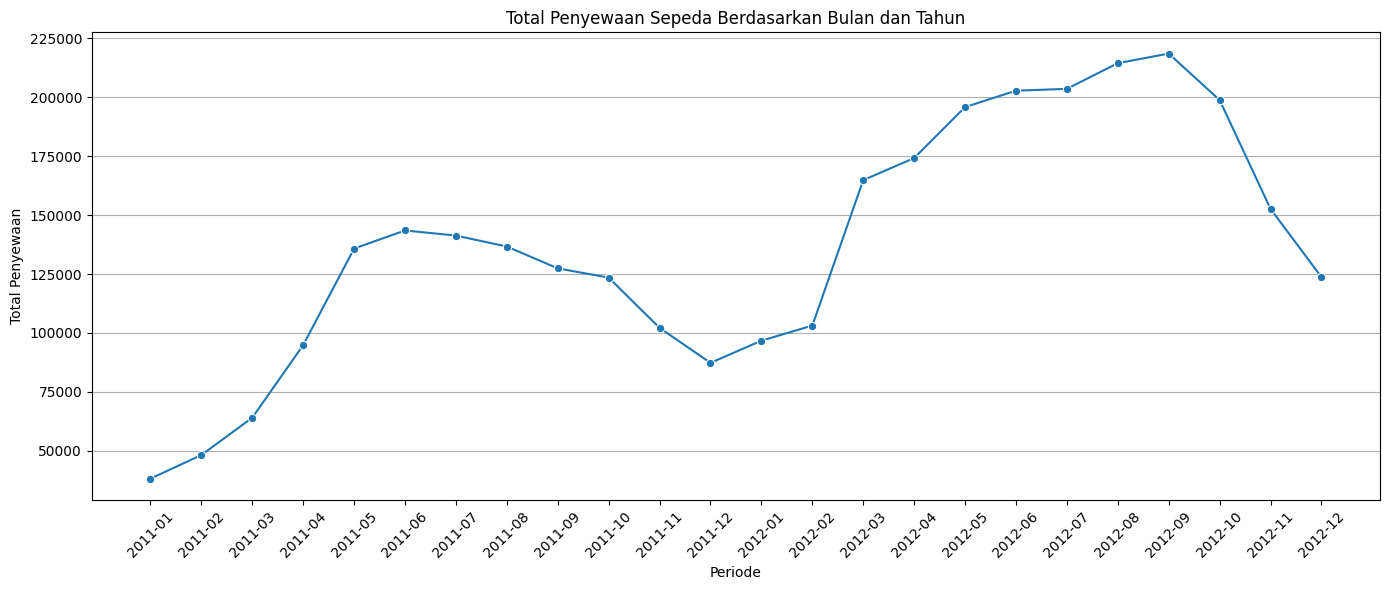

In [83]:
penyewaan_per_bulan = df_day.groupby(['tahun', 'bulan'])['jumlah_penyewaan'].sum().reset_index()

penyewaan_per_bulan['periode'] = penyewaan_per_bulan['tahun'].map({
    0: '2011',
    1: '2012'
}) + '-' + penyewaan_per_bulan['bulan'].astype(str).str.zfill(2)

plt.figure(figsize=(14, 6))
sns.lineplot(data=penyewaan_per_bulan, x='periode', y='jumlah_penyewaan', marker='o')

plt.title('Total Penyewaan Sepeda Berdasarkan Bulan dan Tahun')
plt.xlabel('Periode')
plt.ylabel('Total Penyewaan')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Pertanyaan 4: Kondisi cuaca apa yang memiliki rata-rata jumlah penyewaan sepeda tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?

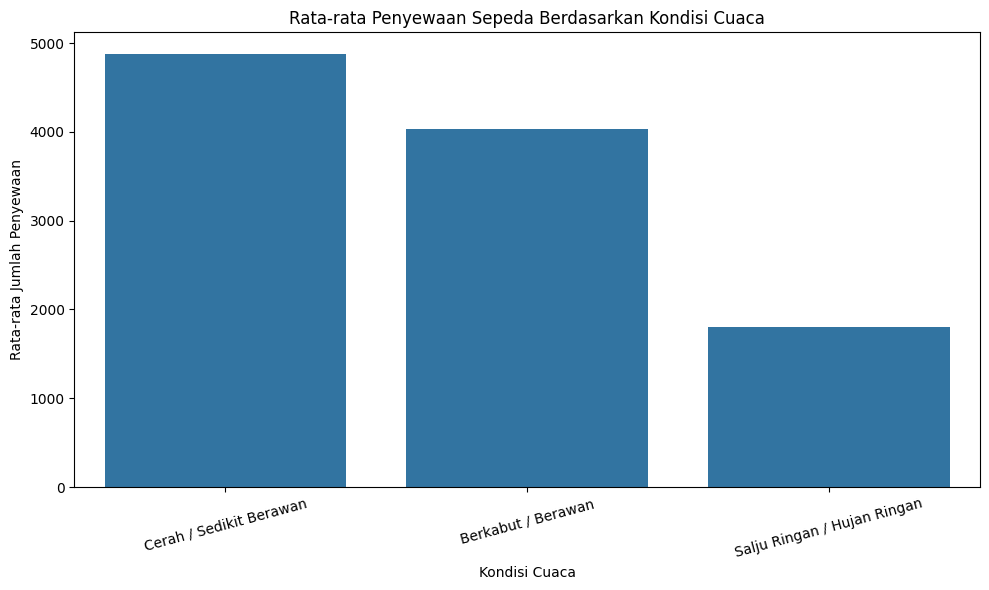

In [84]:
penyewaan_cuaca = df_day.groupby('kondisi_cuaca')['jumlah_penyewaan'].mean().reset_index()

penyewaan_cuaca['kondisi_cuaca'] = penyewaan_cuaca['kondisi_cuaca'].map({
    1: 'Cerah / Sedikit Berawan',
    2: 'Berkabut / Berawan',
    3: 'Salju Ringan / Hujan Ringan',
    4: 'Hujan Lebat / Hujan Es'
})

plt.figure(figsize=(10, 6))
sns.barplot(data=penyewaan_cuaca, x='kondisi_cuaca', y='jumlah_penyewaan')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Rata-rata penyewaan sepeda tertinggi berdasarkan jam terjadi pada pukul 17.00 dengan 461,45 penyewaan, sedangkan terendah terjadi pada pukul 04.00 dengan 6,35 penyewaan.
- Rata-rata penyewaan pada hari kerja sebesar 4.584,82, lebih tinggi dibandingkan hari nonkerja sebesar 4.330,17. Terdapat selisih sebesar 254,65 penyewaan.
- Total penyewaan tertinggi terjadi pada September 2012 dengan 218.573 penyewaan, sedangkan terendah terjadi pada Januari 2011 dengan 38.189 penyewaan.
- Kondisi cuaca kategori 1 memiliki rata-rata penyewaan tertinggi sebesar 4.876,79, sedangkan kategori 3 memiliki rata-rata terendah sebesar 1.803,29.


## Analisis Lanjutan (Opsional)

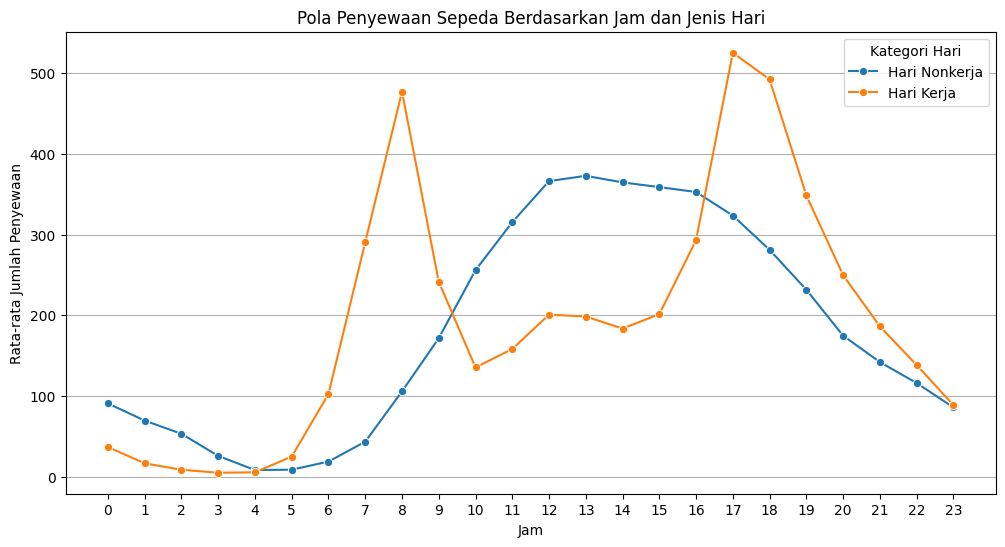

In [85]:
pola_per_jam = df_hour.groupby(
    ['hari_kerja', 'jam']
)['jumlah_penyewaan'].mean().reset_index()

pola_per_jam['hari_kerja'] = pola_per_jam['hari_kerja'].map({
    0: 'Hari Nonkerja',
    1: 'Hari Kerja'
})

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=pola_per_jam,
    x='jam',
    y='jumlah_penyewaan',
    hue='hari_kerja',
    marker='o'
)

plt.title('Pola Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.legend(title='Kategori Hari')
plt.grid(axis='y')
plt.show()

**Insight:** (Opsional)
- Pada hari kerja, penyewaan sepeda memiliki dua periode puncak, yaitu pukul 08.00 dan 17.00. Puncak tertinggi terjadi pada pukul 17.00.
- Pada hari nonkerja, penyewaan sepeda cenderung meningkat pada siang hari dan mencapai puncaknya sekitar pukul 13.00.
- Pola penyewaan pada hari kerja menunjukkan kecenderungan penggunaan sepeda pada jam berangkat dan pulang kerja.
- Sementara itu, pada hari nonkerja, aktivitas penyewaan lebih terkonsentrasi pada siang hingga sore hari.
- Perbedaan pola tersebut menunjukkan bahwa jenis hari berkaitan dengan waktu penggunaan sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00 dengan 461,45 penyewaan, sedangkan rata-rata terendah terjadi pada pukul 04.00 dengan 6,35 penyewaan. Hal ini menunjukkan bahwa aktivitas penyewaan sepeda paling tinggi terjadi pada sore hari.

- **Conclusion pertanyaan 2:** Rata-rata penyewaan sepeda pada hari kerja working day sebesar 4.584,82, lebih tinggi dibandingkan hari nonkerja non-working day sebesar 4.330,17. Terdapat selisih rata-rata sebesar 254,65 penyewaan.

- **Conclusion pertanyaan 3:** Total penyewaan sepeda tertinggi terjadi pada September 2012 sebanyak 218.573 penyewaan, sedangkan total terendah terjadi pada Januari 2011 sebanyak 38.189 penyewaan.

- **Conclusion pertanyaan 4:** Kondisi cuaca kategori 1 memiliki rata-rata penyewaan tertinggi sebesar 4.876,79, sedangkan kategori 3 memiliki rata-rata terendah sebesar 1.803,29.

**Rekomendasi Action Item:**

- **Mengoptimalkan ketersediaan sepeda pada jam sibuk:** Menambah atau memastikan ketersediaan sepeda pada pukul 07.00–09.00 dan 16.00–18.00, terutama pada hari kerja, untuk memenuhi peningkatan permintaan.

- **Menyesuaikan distribusi sepeda berdasarkan jenis hari:** Mengatur distribusi sepeda dengan mempertimbangkan perbedaan pola penyewaan antara hari kerja dan hari nonkerja. Pada hari nonkerja dapat difokuskan pada periode siang hingga sore hari.

- **Mengantisipasi perubahan permintaan bulanan:** Menyiapkan jumlah sepeda dan kebutuhan operasional lebih banyak menjelang periode dengan permintaan tinggi, terutama sekitar Agustus–September.

- **Memperhatikan kondisi cuaca:** Menyesuaikan strategi operasional berdasarkan kondisi cuaca. Pada kondisi cuaca buruk, pengelola dapat mengantisipasi penurunan permintaan dan tetap memperhatikan keselamatan pengguna.